In [4]:
%pip install --upgrade --force-reinstall librosa numba llvmlite


Defaulting to user installation because normal site-packages is not writeable
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 4.1 MB/s  0:00:004.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 3.7 MB/s  0:00:16 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 3.8 MB/s  0:00:04 eta 0:00:010:00:01
Using cached lazy_loader-0.6-py3-none-any.whl (8.8 kB)
Using cached packaging-26.3-py3-none-any.whl (129 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 2.9 MB/s  0:00:03m 3.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 3.8 MB/s  0:00:09 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━

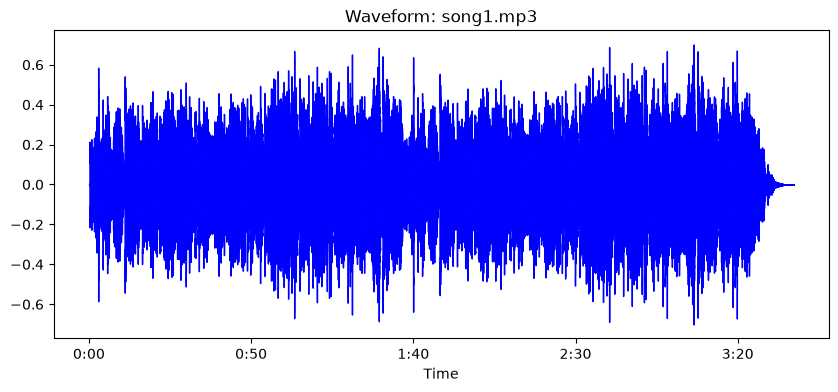

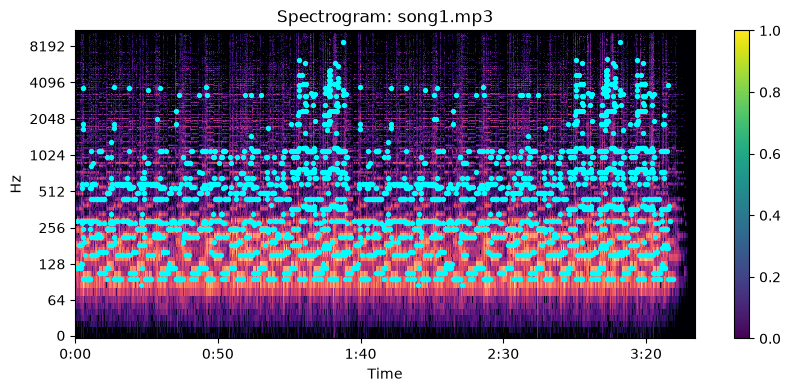

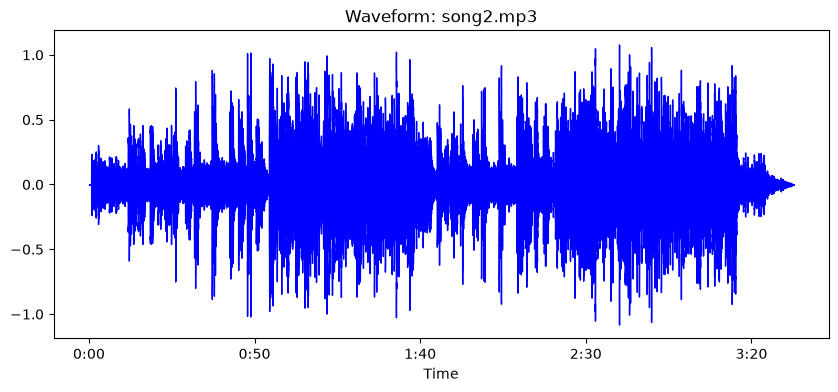

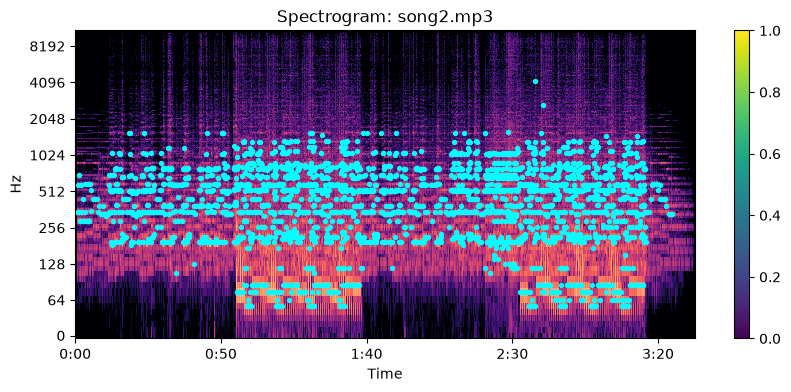

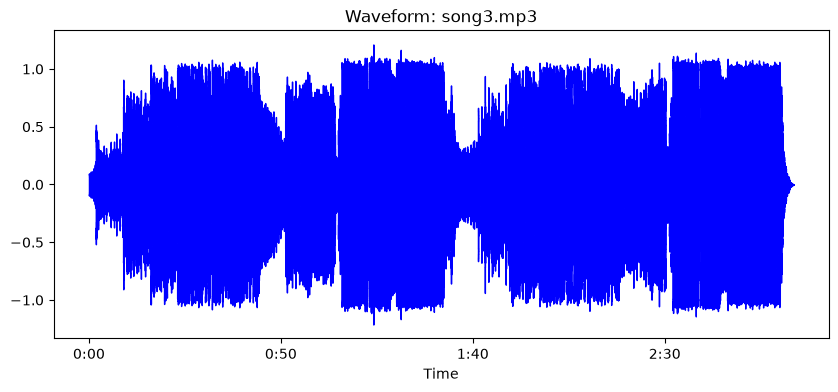

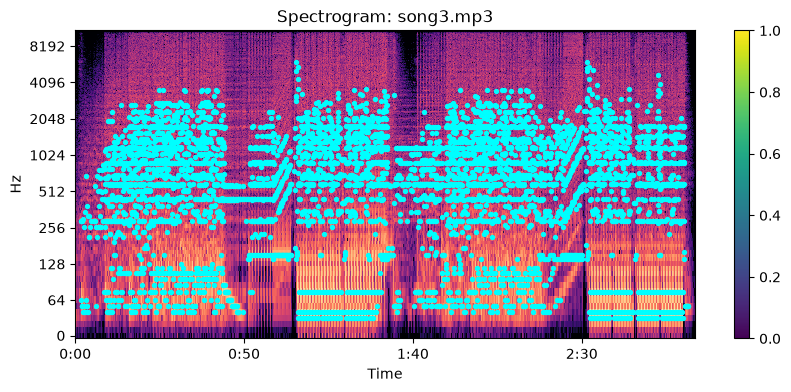

In [11]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import maximum_filter

songs = ["song1.mp3", "song2.mp3", "song3.mp3"]

for song in songs:
    audio, sr = librosa.load(song)
    # waveform plot
    plt.figure(figsize=(10, 4))
    librosa.display.waveshow(audio, sr=sr, color="blue")
    plt.title(f"Waveform: {song}")
    plt.show()

    spectrogram = librosa.amplitude_to_db(np.abs(librosa.stft(audio)), ref=np.max)
    peaks = (maximum_filter(spectrogram, size=(20, 5)) == spectrogram) & (spectrogram >= -25)
    f_idx, t_idx = np.where(peaks)

    plt.figure(figsize=(10, 4))
    librosa.display.specshow(spectrogram, sr=sr, x_axis="time", y_axis="log") # spectrogram plot
    plt.scatter(librosa.frames_to_time(t_idx, sr=sr), librosa.fft_frequencies(sr=sr)[f_idx], c="cyan", s=8) # peaks as cyan points
    plt.colorbar()
    plt.title(f"Spectrogram: {song}")
    plt.show()